# Flight Delay Analysis and Data Visualization Using Python

This project explores flight records from **January 2019 and January 2020** using Python. It uses a reproducible random sample of **5,000 records from each month** (10,000 records combined), rather than the full original datasets.

The notebook uses Pandas for data processing and Matplotlib and Seaborn for visualizations. It compares departure and arrival delays, airline patterns, scheduled departure periods, cancellations, and diversions. Because the data covers January only and uses a sample, the results should not be treated as full-year estimates.


## 1. Project title and imports

In [49]:
print("Flight Delay Analysis")
print("My Python environment is ready!")

Flight Delay Analysis
My Python environment is ready!


In [50]:
import os
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


## 2. Load the datasets

In [51]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [52]:
# STEP 1: LOAD THE SAMPLE DATASETS
import os
import glob
import zipfile
import pandas as pd

sample_files = ["Jan_2019_sample.csv", "Jan_2020_sample.csv"]

# Look first for already-extracted sample CSVs.
folder_candidates = [
    "/content/flight_data",
    "/content/flight_sample_data",
    "/content",
    "/content/drive/MyDrive/Flight_Delay_Project"
]

data_folder = next(
    (
        folder for folder in folder_candidates
        if all(os.path.isfile(os.path.join(folder, name)) for name in sample_files)
    ),
    None
)

if data_folder is not None:
    df_2019 = pd.read_csv(os.path.join(data_folder, sample_files[0]))
    df_2020 = pd.read_csv(os.path.join(data_folder, sample_files[1]))
else:
    # If the sample CSVs are not extracted, look for the reduced sample ZIP.
    zip_candidates = [
        "/content/flight_delay_sample.zip",
        "/content/flight_delay_sample (2).zip",
        "/content/drive/MyDrive/Flight_Delay_Project/flight_delay_sample.zip"
    ]
    zip_candidates.extend(glob.glob("/content/flight_delay_sample*.zip"))

    zip_path = next((p for p in zip_candidates if os.path.isfile(p)), None)

    if zip_path is None:
        raise FileNotFoundError(
            "Could not find the sample CSV files or flight_delay_sample.zip. "
            "Upload flight_delay_sample.zip to Colab and extract it, or place both "
            "sample CSV files in /content/flight_data. This notebook expects the "
            "sample files, not the original full-data CSV files."
        )

    with zipfile.ZipFile(zip_path, "r") as z:
        zip_names = set(z.namelist())
        missing = [name for name in sample_files if name not in zip_names]
        if missing:
            raise FileNotFoundError(
                f"The ZIP {os.path.basename(zip_path)} does not contain: {missing}. "
                "Please use flight_delay_sample.zip."
            )
        with z.open(sample_files[0]) as f:
            df_2019 = pd.read_csv(f)
        with z.open(sample_files[1]) as f:
            df_2020 = pd.read_csv(f)

df_2019["YEAR"] = 2019
df_2020["YEAR"] = 2020

df = pd.concat([df_2019, df_2020], ignore_index=True)

print("Sample datasets loaded successfully!")
print("2019 sample shape:", df_2019.shape)
print("2020 sample shape:", df_2020.shape)
print("Combined sample shape:", df.shape)
display(df.head())


Sample datasets loaded successfully!
2019 sample shape: (5000, 23)
2020 sample shape: (5000, 23)
Combined sample shape: (10000, 23)


,DAY_OF_MONTH,DAY_OF_WEEK,OP_UNIQUE_CARRIER,OP_CARRIER_AIRLINE_ID,OP_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN,...,DEP_TIME,DEP_DEL15,DEP_TIME_BLK,ARR_TIME,ARR_DEL15,CANCELLED,DIVERTED,DISTANCE,Unnamed: 21,YEAR
0,3,4,AS,19930,AS,N365VA,1027,12892,1289208,LAX,...,935.0,0.0,0900-0959,1107.0,0.0,0.0,0.0,337.0,NaN,2019
1,2,3,HA,19690,HA,N491HA,397,12758,1275804,KOA,...,1817.0,0.0,1800-1859,1903.0,0.0,0.0,0.0,163.0,NaN,2019
2,14,1,DL,19790,DL,N920AT,2466,11433,1143302,DTW,...,843.0,0.0,0800-0859,1023.0,0.0,0.0,0.0,926.0,NaN,2019
3,7,1,9E,20363,9E,N676CA,5235,12953,1295304,LGA,...,645.0,0.0,0600-0659,840.0,0.0,0.0,0.0,585.0,NaN,2019
4,9,3,OO,20304,OO,N764SK,2958,14107,1410702,PHX,...,1759.0,0.0,1800-1859,1849.0,0.0,0.0,0.0,119.0,NaN,2019


## 3. Explore the data

In [53]:
# Display the first 5 rows
print("FIRST 5 FLIGHT RECORDS")
display(df.head())

# Display the number of rows and columns
print("DATASET SHAPE")
print(df.shape)

# Display all column names
print("COLUMN NAMES")
print(df.columns.tolist())

FIRST 5 FLIGHT RECORDS


,DAY_OF_MONTH,DAY_OF_WEEK,OP_UNIQUE_CARRIER,OP_CARRIER_AIRLINE_ID,OP_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN,...,DEP_TIME,DEP_DEL15,DEP_TIME_BLK,ARR_TIME,ARR_DEL15,CANCELLED,DIVERTED,DISTANCE,Unnamed: 21,YEAR
0,3,4,AS,19930,AS,N365VA,1027,12892,1289208,LAX,...,935.0,0.0,0900-0959,1107.0,0.0,0.0,0.0,337.0,NaN,2019
1,2,3,HA,19690,HA,N491HA,397,12758,1275804,KOA,...,1817.0,0.0,1800-1859,1903.0,0.0,0.0,0.0,163.0,NaN,2019
2,14,1,DL,19790,DL,N920AT,2466,11433,1143302,DTW,...,843.0,0.0,0800-0859,1023.0,0.0,0.0,0.0,926.0,NaN,2019
3,7,1,9E,20363,9E,N676CA,5235,12953,1295304,LGA,...,645.0,0.0,0600-0659,840.0,0.0,0.0,0.0,585.0,NaN,2019
4,9,3,OO,20304,OO,N764SK,2958,14107,1410702,PHX,...,1759.0,0.0,1800-1859,1849.0,0.0,0.0,0.0,119.0,NaN,2019


DATASET SHAPE
(10000, 23)
COLUMN NAMES
['DAY_OF_MONTH', 'DAY_OF_WEEK', 'OP_UNIQUE_CARRIER', 'OP_CARRIER_AIRLINE_ID', 'OP_CARRIER', 'TAIL_NUM', 'OP_CARRIER_FL_NUM', 'ORIGIN_AIRPORT_ID', 'ORIGIN_AIRPORT_SEQ_ID', 'ORIGIN', 'DEST_AIRPORT_ID', 'DEST_AIRPORT_SEQ_ID', 'DEST', 'DEP_TIME', 'DEP_DEL15', 'DEP_TIME_BLK', 'ARR_TIME', 'ARR_DEL15', 'CANCELLED', 'DIVERTED', 'DISTANCE', 'Unnamed: 21', 'YEAR']


In [54]:
# Check missing values in each column
print("MISSING VALUES IN EACH COLUMN")

print(df.isnull().sum())

MISSING VALUES IN EACH COLUMN
DAY_OF_MONTH                 0
DAY_OF_WEEK                  0
OP_UNIQUE_CARRIER            0
OP_CARRIER_AIRLINE_ID        0
OP_CARRIER                   0
TAIL_NUM                    22
OP_CARRIER_FL_NUM            0
ORIGIN_AIRPORT_ID            0
ORIGIN_AIRPORT_SEQ_ID        0
ORIGIN                       0
DEST_AIRPORT_ID              0
DEST_AIRPORT_SEQ_ID          0
DEST                         0
DEP_TIME                   211
DEP_DEL15                  211
DEP_TIME_BLK                 0
ARR_TIME                   218
ARR_DEL15                  234
CANCELLED                    0
DIVERTED                     0
DISTANCE                     0
Unnamed: 21              10000
YEAR                         0
dtype: int64


In [55]:
# Display the data type of each column
print("DATA TYPES OF ALL COLUMNS")

print(df.dtypes)

# Display basic information about the dataset
print("\nDATASET INFORMATION")

df.info()

DATA TYPES OF ALL COLUMNS
DAY_OF_MONTH               int64
DAY_OF_WEEK                int64
OP_UNIQUE_CARRIER         object
OP_CARRIER_AIRLINE_ID      int64
OP_CARRIER                object
TAIL_NUM                  object
OP_CARRIER_FL_NUM          int64
ORIGIN_AIRPORT_ID          int64
ORIGIN_AIRPORT_SEQ_ID      int64
ORIGIN                    object
DEST_AIRPORT_ID            int64
DEST_AIRPORT_SEQ_ID        int64
DEST                      object
DEP_TIME                 float64
DEP_DEL15                float64
DEP_TIME_BLK              object
ARR_TIME                 float64
ARR_DEL15                float64
CANCELLED                float64
DIVERTED                 float64
DISTANCE                 float64
Unnamed: 21              float64
YEAR                       int64
dtype: object

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------         

## 4. Clean the data

In [56]:
# Check the original dataset size
print("Original dataset shape:", df.shape)

# Remove completely empty columns
df = df.dropna(axis=1, how='all')

# Display the updated dataset size
print("Dataset shape after removing empty columns:", df.shape)

# Display the remaining column names
print("Remaining columns:")
print(df.columns.tolist())

Original dataset shape: (10000, 23)
Dataset shape after removing empty columns: (10000, 22)
Remaining columns:
['DAY_OF_MONTH', 'DAY_OF_WEEK', 'OP_UNIQUE_CARRIER', 'OP_CARRIER_AIRLINE_ID', 'OP_CARRIER', 'TAIL_NUM', 'OP_CARRIER_FL_NUM', 'ORIGIN_AIRPORT_ID', 'ORIGIN_AIRPORT_SEQ_ID', 'ORIGIN', 'DEST_AIRPORT_ID', 'DEST_AIRPORT_SEQ_ID', 'DEST', 'DEP_TIME', 'DEP_DEL15', 'DEP_TIME_BLK', 'ARR_TIME', 'ARR_DEL15', 'CANCELLED', 'DIVERTED', 'DISTANCE', 'YEAR']


In [57]:
# STEP 2: DATA CLEANING

# 1. Check the original dataset size
print("Original dataset shape:", df.shape)

# 2. Check duplicate records
print("Duplicate records:", df.duplicated().sum())

# 3. Remove duplicate records
df = df.drop_duplicates()

# 4. Display the dataset size after removing duplicates
print("Dataset shape after removing duplicates:", df.shape)

# 5. Check missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# 6. Calculate the percentage of missing values
print("\nMissing value percentage:")
print((df.isnull().sum() / len(df) * 100).round(2))

Original dataset shape: (10000, 22)
Duplicate records: 0
Dataset shape after removing duplicates: (10000, 22)

Missing values in each column:
DAY_OF_MONTH               0
DAY_OF_WEEK                0
OP_UNIQUE_CARRIER          0
OP_CARRIER_AIRLINE_ID      0
OP_CARRIER                 0
TAIL_NUM                  22
OP_CARRIER_FL_NUM          0
ORIGIN_AIRPORT_ID          0
ORIGIN_AIRPORT_SEQ_ID      0
ORIGIN                     0
DEST_AIRPORT_ID            0
DEST_AIRPORT_SEQ_ID        0
DEST                       0
DEP_TIME                 211
DEP_DEL15                211
DEP_TIME_BLK               0
ARR_TIME                 218
ARR_DEL15                234
CANCELLED                  0
DIVERTED                   0
DISTANCE                   0
YEAR                       0
dtype: int64

Missing value percentage:
DAY_OF_MONTH             0.00
DAY_OF_WEEK              0.00
OP_UNIQUE_CARRIER        0.00
OP_CARRIER_AIRLINE_ID    0.00
OP_CARRIER               0.00
TAIL_NUM                 0.22


In [58]:
missing_percentage = (
    df.isnull().sum() / len(df) * 100
).round(2)

print("MISSING VALUE PERCENTAGES")
print(missing_percentage[missing_percentage > 0])

MISSING VALUE PERCENTAGES
TAIL_NUM     0.22
DEP_TIME     2.11
DEP_DEL15    2.11
ARR_TIME     2.18
ARR_DEL15    2.34
dtype: float64


## 5. Prepare data for analysis

In [59]:
# STEP 3: PREPARE DATA FOR ANALYSIS

# Keep the original dataset unchanged
analysis_df = df.copy()

# Remove the completely empty column if it still exists
analysis_df = analysis_df.dropna(axis=1, how="all")

# Keep records with valid departure and arrival delay indicators
analysis_df = analysis_df.dropna(
    subset=["DEP_DEL15", "ARR_DEL15"]
)

# Display the updated dataset information
print("Original dataset shape:", df.shape)
print("Analysis dataset shape:", analysis_df.shape)

print("\nMissing values in delay columns:")
print(analysis_df[["DEP_DEL15", "ARR_DEL15"]].isnull().sum())

print("\nFirst five records:")
display(analysis_df.head())

Original dataset shape: (10000, 22)
Analysis dataset shape: (9766, 22)

Missing values in delay columns:
DEP_DEL15    0
ARR_DEL15    0
dtype: int64

First five records:


,DAY_OF_MONTH,DAY_OF_WEEK,OP_UNIQUE_CARRIER,OP_CARRIER_AIRLINE_ID,OP_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN,...,DEST,DEP_TIME,DEP_DEL15,DEP_TIME_BLK,ARR_TIME,ARR_DEL15,CANCELLED,DIVERTED,DISTANCE,YEAR
0,3,4,AS,19930,AS,N365VA,1027,12892,1289208,LAX,...,SFO,935.0,0.0,0900-0959,1107.0,0.0,0.0,0.0,337.0,2019
1,2,3,HA,19690,HA,N491HA,397,12758,1275804,KOA,...,HNL,1817.0,0.0,1800-1859,1903.0,0.0,0.0,0.0,163.0,2019
2,14,1,DL,19790,DL,N920AT,2466,11433,1143302,DTW,...,MSY,843.0,0.0,0800-0859,1023.0,0.0,0.0,0.0,926.0,2019
3,7,1,9E,20363,9E,N676CA,5235,12953,1295304,LGA,...,CVG,645.0,0.0,0600-0659,840.0,0.0,0.0,0.0,585.0,2019
4,9,3,OO,20304,OO,N764SK,2958,14107,1410702,PHX,...,FLG,1759.0,0.0,1800-1859,1849.0,0.0,0.0,0.0,119.0,2019


In [60]:
# Check the cleaned dataset
print("Cleaned Dataset Information:")
print("Number of rows:", analysis_df.shape[0])
print("Number of columns:", analysis_df.shape[1])

print("\nMissing Values in Delay Columns:")
print("Departure delay missing:", analysis_df['DEP_DEL15'].isnull().sum())
print("Arrival delay missing:", analysis_df['ARR_DEL15'].isnull().sum())

print("\nFirst 5 Records:")
display(analysis_df.head())

Cleaned Dataset Information:
Number of rows: 9766
Number of columns: 22

Missing Values in Delay Columns:
Departure delay missing: 0
Arrival delay missing: 0

First 5 Records:


,DAY_OF_MONTH,DAY_OF_WEEK,OP_UNIQUE_CARRIER,OP_CARRIER_AIRLINE_ID,OP_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN,...,DEST,DEP_TIME,DEP_DEL15,DEP_TIME_BLK,ARR_TIME,ARR_DEL15,CANCELLED,DIVERTED,DISTANCE,YEAR
0,3,4,AS,19930,AS,N365VA,1027,12892,1289208,LAX,...,SFO,935.0,0.0,0900-0959,1107.0,0.0,0.0,0.0,337.0,2019
1,2,3,HA,19690,HA,N491HA,397,12758,1275804,KOA,...,HNL,1817.0,0.0,1800-1859,1903.0,0.0,0.0,0.0,163.0,2019
2,14,1,DL,19790,DL,N920AT,2466,11433,1143302,DTW,...,MSY,843.0,0.0,0800-0859,1023.0,0.0,0.0,0.0,926.0,2019
3,7,1,9E,20363,9E,N676CA,5235,12953,1295304,LGA,...,CVG,645.0,0.0,0600-0659,840.0,0.0,0.0,0.0,585.0,2019
4,9,3,OO,20304,OO,N764SK,2958,14107,1410702,PHX,...,FLG,1759.0,0.0,1800-1859,1849.0,0.0,0.0,0.0,119.0,2019


## 6. Analyze flight delays

In [61]:

# Flight Delay Percentage Analysis

print("Departure Delay Analysis:")
departure_delayed = (analysis_df['DEP_DEL15'] == 1).sum()
total_flights = len(analysis_df)
departure_percentage = (departure_delayed / total_flights) * 100

print("Total flights:", total_flights)
print("Delayed departures:", departure_delayed)
print("Departure delay percentage:", round(departure_percentage, 2), "%")

print("\nArrival Delay Analysis:")
arrival_delayed = (analysis_df['ARR_DEL15'] == 1).sum()
arrival_percentage = (arrival_delayed / total_flights) * 100

print("Delayed arrivals:", arrival_delayed)
print("Arrival delay percentage:", round(arrival_percentage, 2), "%")


Departure Delay Analysis:
Total flights: 9766
Delayed departures: 1542
Departure delay percentage: 15.79 %

Arrival Delay Analysis:
Delayed arrivals: 1611
Arrival delay percentage: 16.5 %


In [80]:

# Airline-wise departure delay analysis

airline_delays = (
    analysis_df.groupby('OP_CARRIER')
    .agg(
        Total_Flights=('DEP_DEL15', 'count'),
        Delayed_Flights=('DEP_DEL15', 'sum')
    )
)

airline_delays['Delay_Percentage'] = (
    airline_delays['Delayed_Flights']
    / airline_delays['Total_Flights'] * 100
)

airline_delays = airline_delays.sort_values(
    'Delay_Percentage', ascending=False
)

display(airline_delays.round(2))


,Total_Flights,Delayed_Flights,Delay_Percentage
OP_CARRIER,,,
F9,192,41.0,21.35
EV,207,43.0,20.77
B6,399,78.0,19.55
MQ,366,68.0,18.58
OO,1142,210.0,18.39
9E,354,64.0,18.08
AS,355,61.0,17.18
OH,381,62.0,16.27
WN,1785,283.0,15.85


In [63]:

# Arrival delay analysis by airline

arrival_airline_delays = (
    analysis_df.groupby('OP_CARRIER')
    .agg(
        Total_Flights=('ARR_DEL15', 'count'),
        Delayed_Arrivals=('ARR_DEL15', 'sum')
    )
)

arrival_airline_delays['Arrival_Delay_Percentage'] = (
    arrival_airline_delays['Delayed_Arrivals']
    / arrival_airline_delays['Total_Flights'] * 100
)

arrival_airline_delays = arrival_airline_delays.sort_values(
    'Arrival_Delay_Percentage', ascending=False
)

display(arrival_airline_delays.round(2))


,Total_Flights,Delayed_Arrivals,Arrival_Delay_Percentage
OP_CARRIER,,,
MQ,366,98.0,26.78
AS,355,79.0,22.25
EV,207,45.0,21.74
F9,192,39.0,20.31
B6,399,79.0,19.80
OO,1142,221.0,19.35
AA,1275,220.0,17.25
G4,112,19.0,16.96
UA,804,132.0,16.42


In [64]:
# Count cancelled flights
cancelled_flights = (df['CANCELLED'] == 1).sum()
total_flights = len(df)

# Calculate cancellation percentage
cancellation_percentage = (cancelled_flights / total_flights) * 100

print("Total flights:", total_flights)
print("Cancelled flights:", cancelled_flights)
print("Cancellation percentage:", round(cancellation_percentage, 2), "%")

Total flights: 10000
Cancelled flights: 217
Cancellation percentage: 2.17 %


In [65]:
# Count diverted flights
diverted_flights = (df['DIVERTED'] == 1).sum()
total_flights = len(df)

# Calculate diversion percentage
diversion_percentage = (diverted_flights / total_flights) * 100

print("Total flights:", total_flights)
print("Diverted flights:", diverted_flights)
print("Diversion percentage:", round(diversion_percentage, 2), "%")


Total flights: 10000
Diverted flights: 17
Diversion percentage: 0.17 %


## 7. Create visualizations

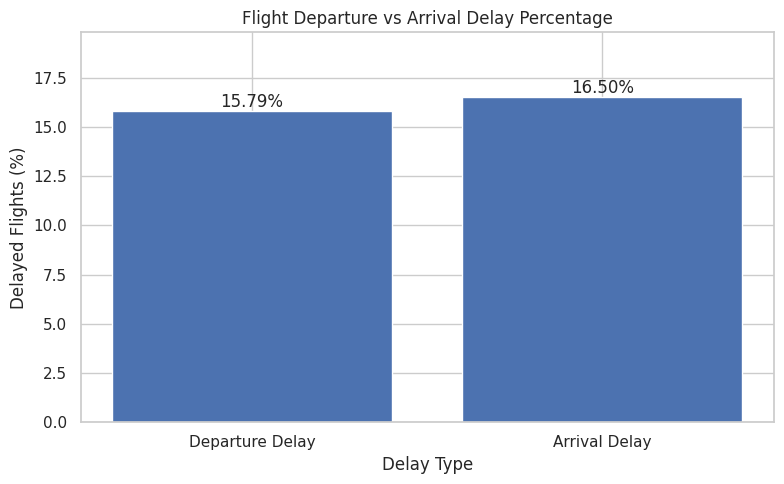

In [66]:


# Compare departure and arrival delay percentages
delay_types = ['Departure Delay', 'Arrival Delay']
delay_percentages = [departure_percentage, arrival_percentage]

plt.figure(figsize=(8, 5))
bars = plt.bar(delay_types, delay_percentages)

plt.title('Flight Departure vs Arrival Delay Percentage')
plt.xlabel('Delay Type')
plt.ylabel('Delayed Flights (%)')
plt.ylim(0, max(delay_percentages) * 1.2)

# Display percentage values above the bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f'{height:.2f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()


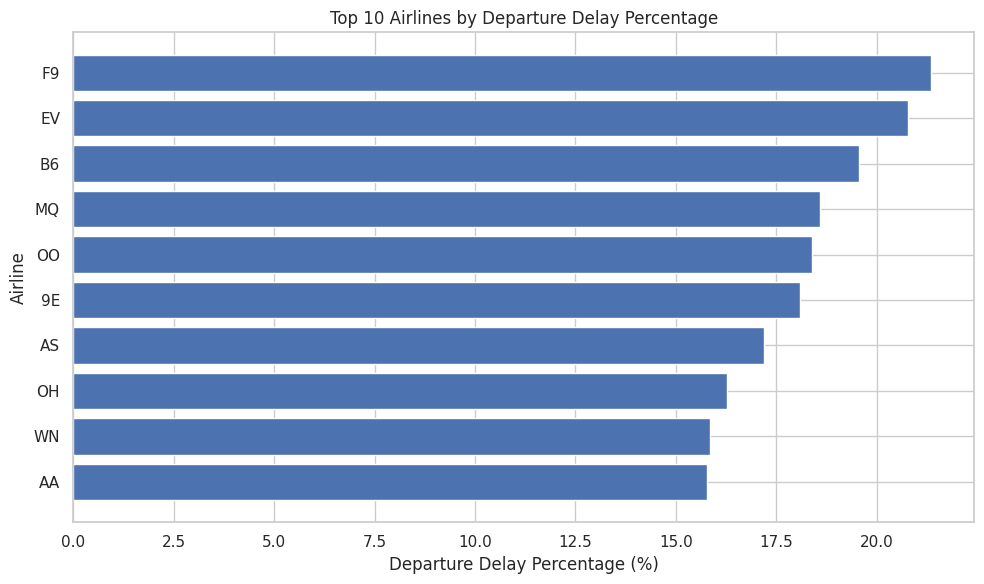

In [67]:


# Select the 10 airlines with the highest departure delay percentages
top_airlines = airline_delays.head(10).sort_values(
    'Delay_Percentage', ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_airlines.index,
    top_airlines['Delay_Percentage']
)

plt.title('Top 10 Airlines by Departure Delay Percentage')
plt.xlabel('Departure Delay Percentage (%)')
plt.ylabel('Airline')

plt.tight_layout()
plt.show()


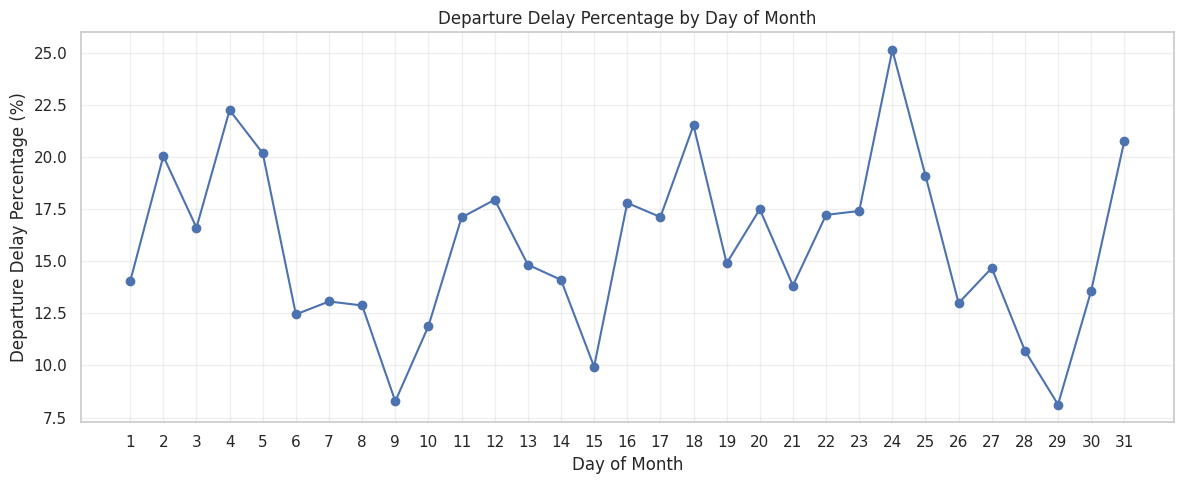

In [68]:

# Monthly flight delay analysis

monthly_delays = analysis_df.groupby('DAY_OF_MONTH').agg(
    Total_Flights=('DEP_DEL15', 'count'),
    Delayed_Flights=('DEP_DEL15', 'sum')
)

monthly_delays['Delay_Percentage'] = (
    monthly_delays['Delayed_Flights']
    / monthly_delays['Total_Flights'] * 100
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_delays.index,
    monthly_delays['Delay_Percentage'],
    marker='o'
)

plt.title('Departure Delay Percentage by Day of Month')
plt.xlabel('Day of Month')
plt.ylabel('Departure Delay Percentage (%)')
plt.xticks(range(1, 32))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


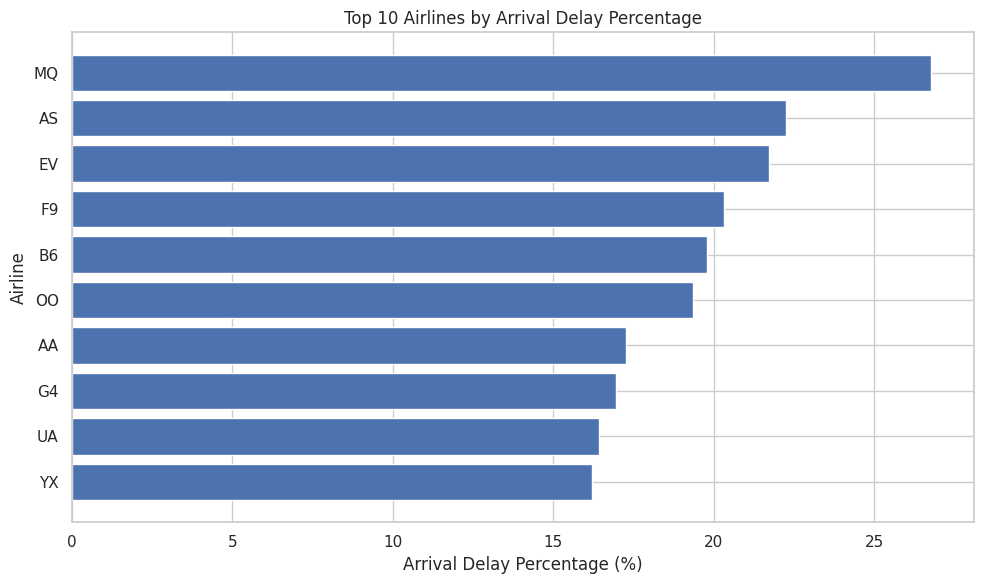

In [69]:

# Top 10 airlines by arrival delay percentage

top_arrival_airlines = arrival_airline_delays.head(10).sort_values(
    'Arrival_Delay_Percentage', ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_arrival_airlines.index,
    top_arrival_airlines['Arrival_Delay_Percentage']
)

plt.title('Top 10 Airlines by Arrival Delay Percentage')
plt.xlabel('Arrival Delay Percentage (%)')
plt.ylabel('Airline')

plt.tight_layout()
plt.show()


Departure delays by day of the week:


,Total_Flights,Delayed_Flights,Delay_Percentage
DAY_OF_WEEK,,,
1,1290,191.0,14.81
2,1437,184.0,12.80
3,1607,228.0,14.19
4,1739,308.0,17.71
5,1456,248.0,17.03
6,1049,186.0,17.73
7,1188,197.0,16.58


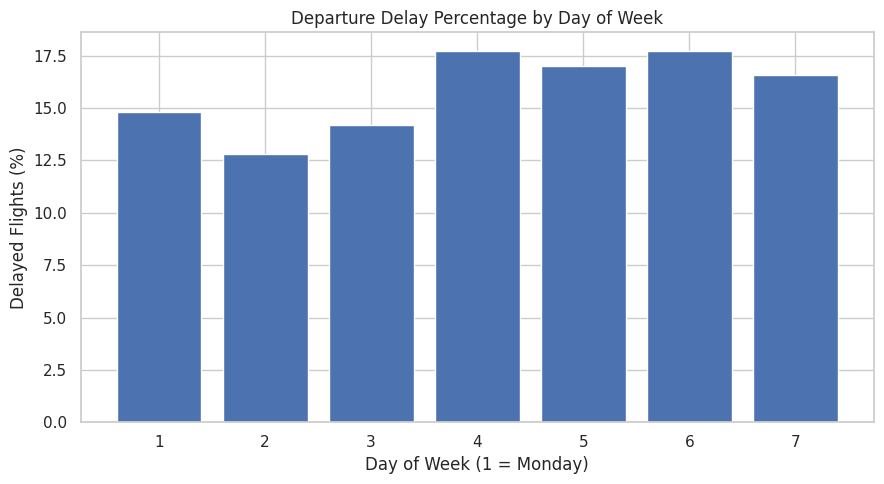

In [70]:

# Departure delay analysis by day of the week

weekday_delays = analysis_df.groupby('DAY_OF_WEEK').agg(
    Total_Flights=('DEP_DEL15', 'count'),
    Delayed_Flights=('DEP_DEL15', 'sum')
)

weekday_delays['Delay_Percentage'] = (
    weekday_delays['Delayed_Flights']
    / weekday_delays['Total_Flights'] * 100
)

print("Departure delays by day of the week:")
display(weekday_delays.round(2))

# Plot the results
plt.figure(figsize=(9, 5))

plt.bar(
    weekday_delays.index,
    weekday_delays['Delay_Percentage']
)

plt.title('Departure Delay Percentage by Day of Week')
plt.xlabel('Day of Week (1 = Monday)')
plt.ylabel('Delayed Flights (%)')
plt.xticks(range(1, 8))
plt.tight_layout()
plt.show()


Top 10 origin airports by departure delay percentage:


,Total_Flights,Delayed_Flights,Delay_Percentage
ORIGIN,,,
SBP,10,4.0,40.00
SYR,14,5.0,35.71
DSM,23,8.0,34.78
EGE,10,3.0,30.00
SBN,10,3.0,30.00
PNS,14,4.0,28.57
ELP,21,6.0,28.57
MDW,85,24.0,28.24
SJU,36,10.0,27.78


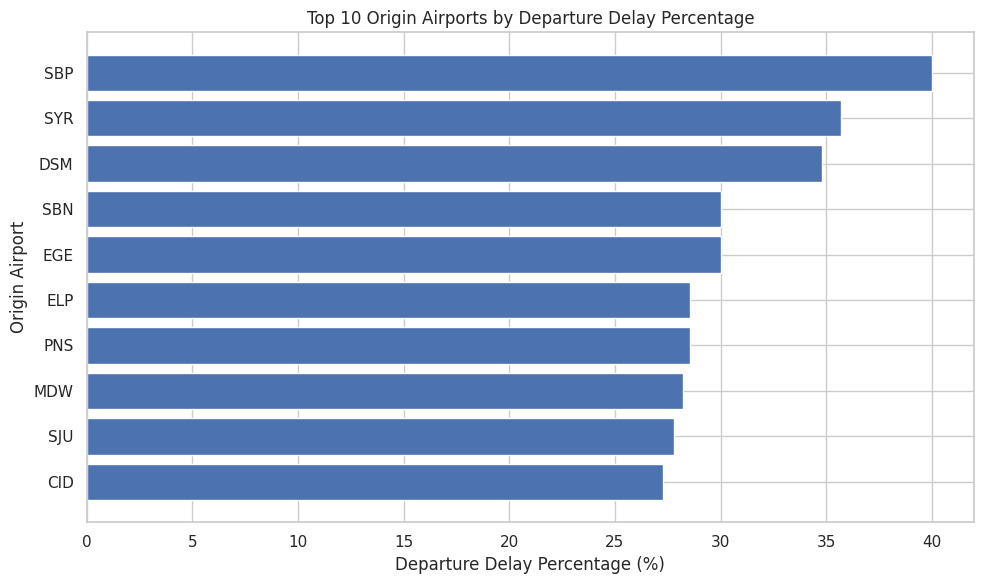

In [71]:

# Departure delay analysis by origin airport

airport_delays = analysis_df.groupby('ORIGIN').agg(
    Total_Flights=('DEP_DEL15', 'count'),
    Delayed_Flights=('DEP_DEL15', 'sum')
)

airport_delays['Delay_Percentage'] = (
    airport_delays['Delayed_Flights']
    / airport_delays['Total_Flights'] * 100
)

# Include airports with at least 10 valid flights
airport_delays = airport_delays[
    airport_delays['Total_Flights'] >= 10
]

airport_delays = airport_delays.sort_values(
    'Delay_Percentage', ascending=False
)

print("Top 10 origin airports by departure delay percentage:")
display(airport_delays.head(10).round(2))

# Visualize the top 10
top_airports = airport_delays.head(10).sort_values(
    'Delay_Percentage', ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_airports.index,
    top_airports['Delay_Percentage']
)

plt.title('Top 10 Origin Airports by Departure Delay Percentage')
plt.xlabel('Departure Delay Percentage (%)')
plt.ylabel('Origin Airport')
plt.tight_layout()
plt.show()


Departure delays by scheduled time block:


,Total_Flights,Delayed_Flights,Delay_Percentage
DEP_TIME_BLK,,,
0001-0559,252,18.0,7.14
0600-0659,721,50.0,6.93
0700-0759,661,54.0,8.17
0800-0859,656,65.0,9.91
0900-0959,563,62.0,11.01
1000-1059,568,82.0,14.44
1100-1159,612,96.0,15.69
1200-1259,603,100.0,16.58
1300-1359,571,99.0,17.34


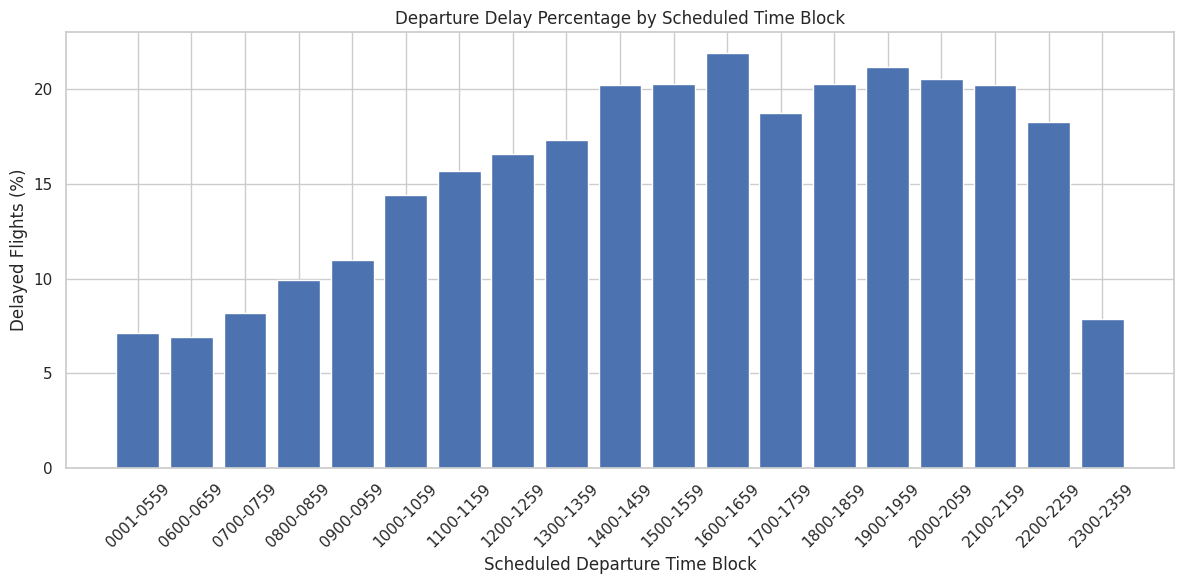

In [72]:


# Keep valid departure delay records
time_df = analysis_df.dropna(
    subset=['DEP_TIME_BLK', 'DEP_DEL15']
).copy()

# Calculate delay percentage for each scheduled departure time block
time_delays = time_df.groupby('DEP_TIME_BLK').agg(
    Total_Flights=('DEP_DEL15', 'count'),
    Delayed_Flights=('DEP_DEL15', 'sum')
)

time_delays['Delay_Percentage'] = (
    time_delays['Delayed_Flights']
    / time_delays['Total_Flights'] * 100
)

print("Departure delays by scheduled time block:")
display(time_delays.round(2))

# Visualize the results
# Matplotlib bar chart avoids Seaborn compatibility issues with empty or unusual categories.
plt.figure(figsize=(12, 6))

plt.bar(
    time_delays.index.astype(str),
    time_delays['Delay_Percentage']
)

plt.title('Departure Delay Percentage by Scheduled Time Block')
plt.xlabel('Scheduled Departure Time Block')
plt.ylabel('Delayed Flights (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


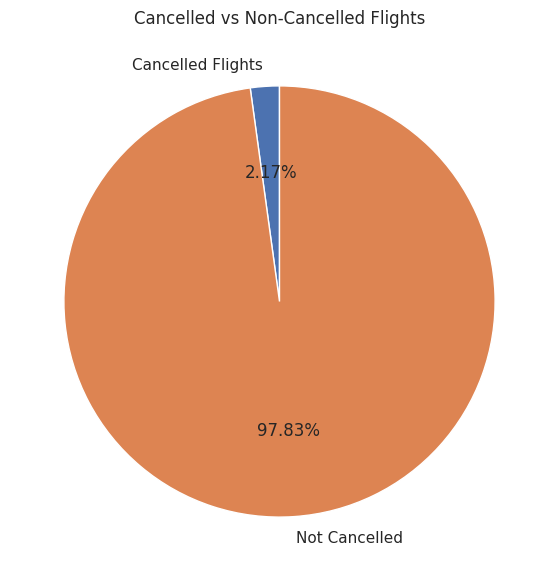

In [73]:

cancelled = (df['CANCELLED'] == 1).sum()
not_cancelled = (df['CANCELLED'] == 0).sum()

labels = ['Cancelled Flights', 'Not Cancelled']
sizes = [cancelled, not_cancelled]

plt.figure(figsize=(7, 7))
plt.pie(
    sizes,
    labels=labels,
    autopct='%1.2f%%',
    startangle=90
)

plt.title('Cancelled vs Non-Cancelled Flights')
plt.show()

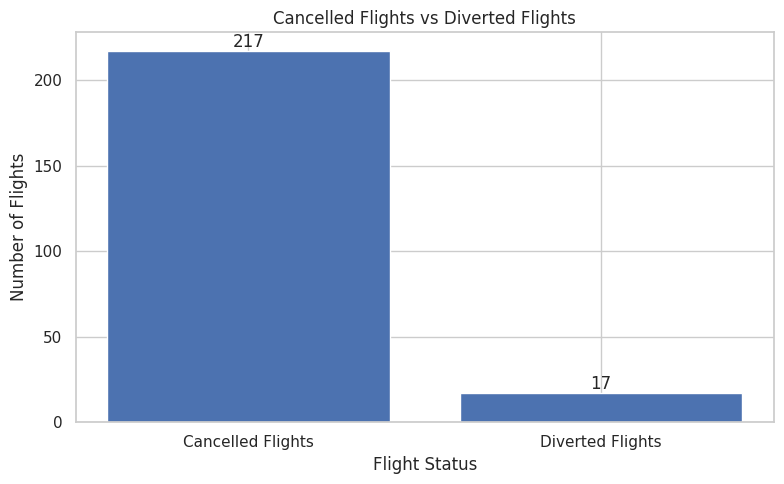

In [74]:

cancelled = (df['CANCELLED'] == 1).sum()
diverted = (df['DIVERTED'] == 1).sum()

categories = ['Cancelled Flights', 'Diverted Flights']
counts = [cancelled, diverted]

plt.figure(figsize=(8, 5))
bars = plt.bar(categories, counts)

plt.title('Cancelled Flights vs Diverted Flights')
plt.xlabel('Flight Status')
plt.ylabel('Number of Flights')

# Display the count above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f'{int(height):,}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

# 9. Flight Delay Analysis Dashboard

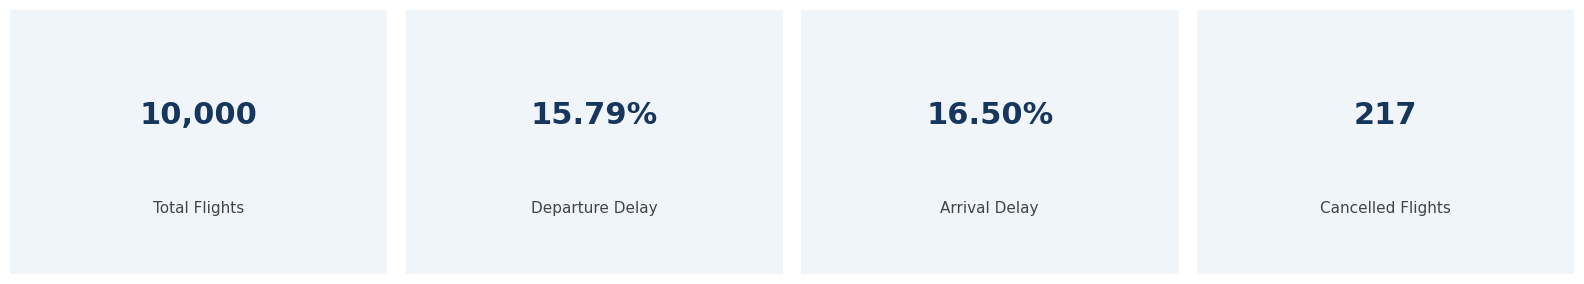

Diverted flights: 17


In [75]:
# STEP 1: DASHBOARD TITLE AND KPI CARDS

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

# Dashboard style
sns.set_theme(style="whitegrid")

# Use the full dataset for total flights and disruptions.
# Use valid delay records for departure and arrival delay percentages.
total_flights = len(df)
cancelled_flights = (df["CANCELLED"] == 1).sum()
diverted_flights = (df["DIVERTED"] == 1).sum()

departure_percentage = (
    (analysis_df["DEP_DEL15"] == 1).sum()
    / analysis_df["DEP_DEL15"].notna().sum()
) * 100

arrival_percentage = (
    (analysis_df["ARR_DEL15"] == 1).sum()
    / analysis_df["ARR_DEL15"].notna().sum()
) * 100

# Display dashboard title
display(HTML("""
<div style="
    background-color:#17365D;
    color:white;
    padding:22px;
    border-radius:10px;
    text-align:center;
    margin-bottom:15px;">
    <h1 style="margin:0;">✈ Flight Delay Analysis Dashboard</h1>
    <p style="margin:8px 0 0 0;">
        January 2019 and January 2020 | Flight Delay Analysis Project
    </p>
</div>
"""))

# Create four KPI cards
metrics = [
    ("Total Flights", f"{total_flights:,}"),
    ("Departure Delay", f"{departure_percentage:.2f}%"),
    ("Arrival Delay", f"{arrival_percentage:.2f}%"),
    ("Cancelled Flights", f"{cancelled_flights:,}")
]

fig, axes = plt.subplots(1, 4, figsize=(16, 3))

for ax, (label, value) in zip(axes, metrics):
    ax.set_facecolor("#F0F5FA")
    ax.text(
        0.5, 0.60, value,
        ha="center", va="center",
        fontsize=22, fontweight="bold",
        color="#17365D"
    )
    ax.text(
        0.5, 0.25, label,
        ha="center", va="center",
        fontsize=11, color="#444444"
    )
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

plt.tight_layout()
plt.show()

print(f"Diverted flights: {diverted_flights:,}")

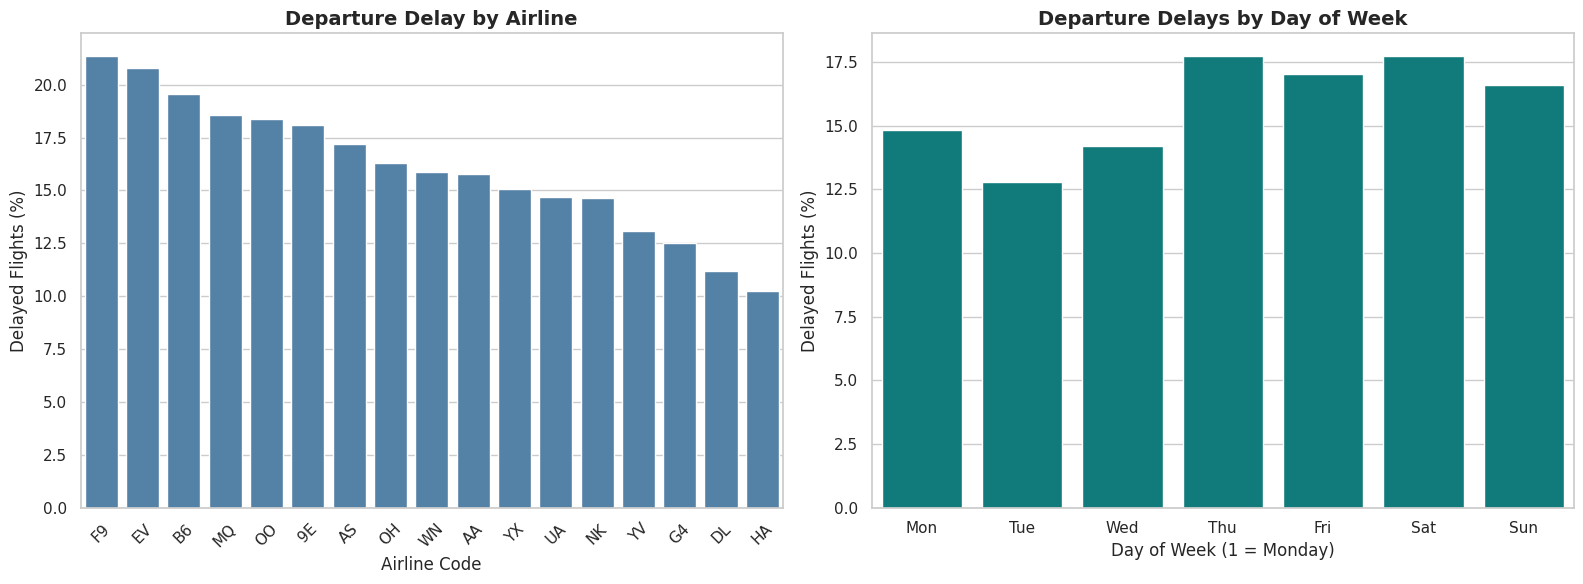

In [76]:
# STEP 2: AIRLINE DELAYS AND WEEKDAY ANALYSIS

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: Departure delay percentage by airline
airline_delays = (
    analysis_df.groupby("OP_UNIQUE_CARRIER")
    .agg(
        Total_Flights=("DEP_DEL15", "count"),
        Delayed_Flights=("DEP_DEL15", lambda x: (x == 1).sum())
    )
)

airline_delays["Delay_Percentage"] = (
    airline_delays["Delayed_Flights"]
    / airline_delays["Total_Flights"] * 100
)

airline_delays = airline_delays.sort_values(
    "Delay_Percentage", ascending=False
)

sns.barplot(
    data=airline_delays.reset_index(),
    x="OP_UNIQUE_CARRIER",
    y="Delay_Percentage",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Departure Delay by Airline", fontsize=14, weight="bold")
axes[0].set_xlabel("Airline Code")
axes[0].set_ylabel("Delayed Flights (%)")
axes[0].tick_params(axis="x", rotation=45)

# Chart 2: Departure delay percentage by day of the week
weekday_delays = (
    analysis_df.groupby("DAY_OF_WEEK")["DEP_DEL15"]
    .agg(
        Total_Flights="count",
        Delayed_Flights=lambda x: (x == 1).sum()
    )
)

weekday_delays["Delay_Percentage"] = (
    weekday_delays["Delayed_Flights"]
    / weekday_delays["Total_Flights"] * 100
)

sns.barplot(
    x=weekday_delays.index,
    y=weekday_delays["Delay_Percentage"],
    ax=axes[1],
    color="darkcyan"
)

axes[1].set_title("Departure Delays by Day of Week", fontsize=14, weight="bold")
axes[1].set_xlabel("Day of Week (1 = Monday)")
axes[1].set_ylabel("Delayed Flights (%)")
axes[1].set_xticks(range(7))
axes[1].set_xticklabels(
    ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
)

plt.tight_layout()
plt.show()

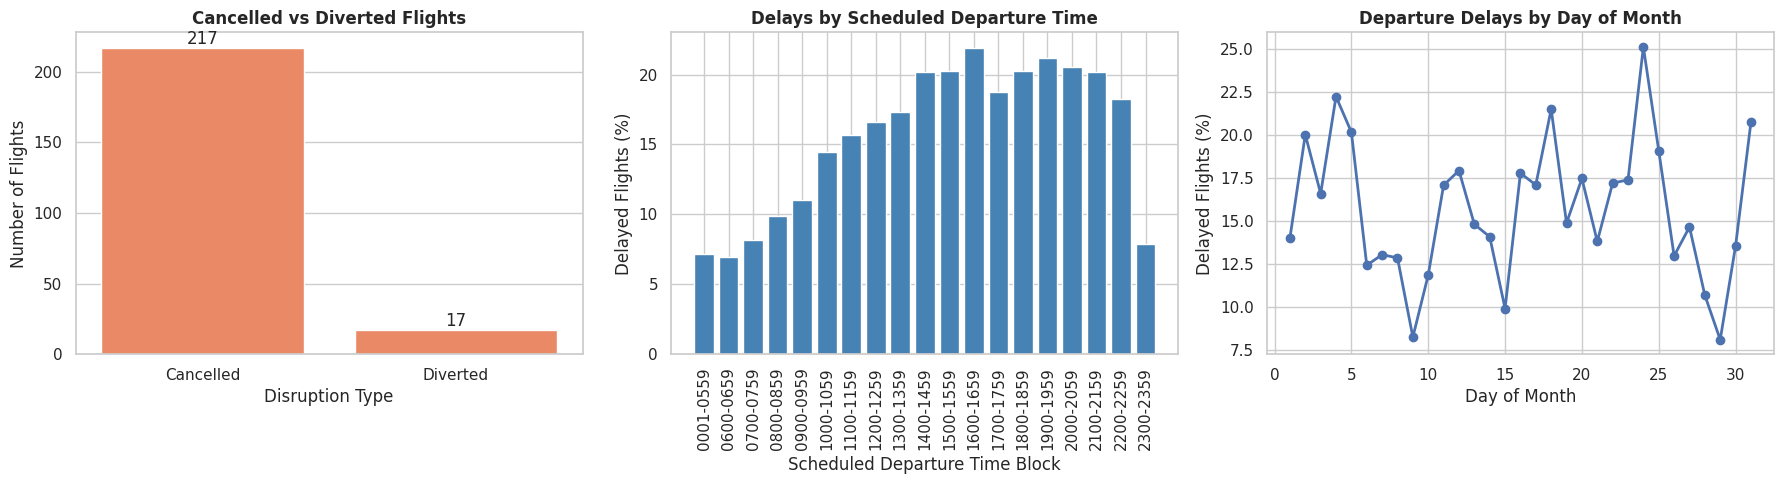

In [77]:
# STEP 3: FLIGHT DISRUPTIONS AND DEPARTURE-TIME ANALYSIS

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chart 1: Cancelled vs diverted flights
disruptions = pd.Series({
    "Cancelled": (df["CANCELLED"] == 1).sum(),
    "Diverted": (df["DIVERTED"] == 1).sum()
})

sns.barplot(
    x=disruptions.index,
    y=disruptions.values,
    ax=axes[0],
    color="coral"
)

axes[0].set_title("Cancelled vs Diverted Flights", weight="bold")
axes[0].set_xlabel("Disruption Type")
axes[0].set_ylabel("Number of Flights")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f")

# Chart 2: Departure delays by scheduled time block
time_delays = (
    analysis_df.groupby("DEP_TIME_BLK")["DEP_DEL15"]
    .agg(
        Total_Flights="count",
        Delayed_Flights=lambda x: (x == 1).sum()
    )
)

time_delays["Delay_Percentage"] = (
    time_delays["Delayed_Flights"]
    / time_delays["Total_Flights"] * 100
)

time_delays = time_delays.sort_index()

axes[1].bar(
    time_delays.index.astype(str),
    time_delays["Delay_Percentage"],
    color="steelblue"
)

axes[1].set_title("Delays by Scheduled Departure Time", weight="bold")
axes[1].set_xlabel("Scheduled Departure Time Block")
axes[1].set_ylabel("Delayed Flights (%)")
axes[1].tick_params(axis="x", rotation=90)

# Chart 3: Departure delay percentage by day of month
daily_delays = (
    analysis_df.groupby("DAY_OF_MONTH")["DEP_DEL15"]
    .agg(
        Total_Flights="count",
        Delayed_Flights=lambda x: (x == 1).sum()
    )
)

daily_delays["Delay_Percentage"] = (
    daily_delays["Delayed_Flights"]
    / daily_delays["Total_Flights"] * 100
)

axes[2].plot(
    daily_delays.index,
    daily_delays["Delay_Percentage"],
    marker="o",
    linewidth=2
)

axes[2].set_title("Departure Delays by Day of Month", weight="bold")
axes[2].set_xlabel("Day of Month")
axes[2].set_ylabel("Delayed Flights (%)")

plt.tight_layout()
plt.show()

In [78]:
# STEP 4: PROFESSIONAL DASHBOARD INSIGHTS

from IPython.display import display, HTML

# Calculate the highest observed categories from the current sample.
worst_airline = airline_delays["Delay_Percentage"].idxmax()
worst_airline_rate = airline_delays["Delay_Percentage"].max()

worst_weekday = int(weekday_delays["Delay_Percentage"].idxmax())
worst_weekday_rate = weekday_delays["Delay_Percentage"].max()

worst_time = time_delays["Delay_Percentage"].idxmax()
worst_time_rate = time_delays["Delay_Percentage"].max()

display(HTML(f"""
<div style="
    background-color:#172B4D;
    color:#FFFFFF;
    padding:28px;
    border-radius:14px;
    font-family:Arial, sans-serif;
    line-height:1.8;
    margin-top:20px;
    border:1px solid #344563;">

    <h2 style="
        color:#7DD3FC;
        font-size:26px;
        margin-top:0;
        border-bottom:2px solid #38BDF8;
        padding-bottom:12px;">
        ✈ KEY INSIGHTS
    </h2>

    <p><b style="color:#7DD3FC;">Departure delays:</b>
    {departure_percentage:.2f}% of flights with recorded departure-delay
    status were delayed by 15 minutes or more.</p>

    <p><b style="color:#7DD3FC;">Arrival delays:</b>
    {arrival_percentage:.2f}% of flights with recorded arrival-delay
    status were delayed by 15 minutes or more.</p>

    <p><b style="color:#7DD3FC;">Airline comparison:</b>
    Airline {worst_airline} had the highest observed departure-delay
    percentage ({worst_airline_rate:.2f}%).</p>

    <p><b style="color:#7DD3FC;">Weekday comparison:</b>
    Day {worst_weekday} had the highest observed departure-delay
    percentage ({worst_weekday_rate:.2f}%).</p>

    <p><b style="color:#7DD3FC;">Departure time:</b>
    Time block {worst_time} had the highest observed departure-delay
    percentage ({worst_time_rate:.2f}%).</p>

    <p><b style="color:#7DD3FC;">Flight disruptions:</b>
    {cancelled_flights:,} flights were cancelled and
    {diverted_flights:,} were diverted.</p>



    <p style="
        color:#BAE6FD;
        font-size:13px;
        margin-bottom:0;
        border-top:1px solid #475569;
        padding-top:12px;">
        Flight Delay Analysis Project | Python, Pandas,
Matplotlib and Seaborn
    </p>
</div>
"""))

## 8. Summary of Results

In [79]:

summary = pd.DataFrame({
    'Metric': [
        'Total Flights',
        'Departure Delay Percentage',
        'Arrival Delay Percentage',
        'Cancelled Flights',
        'Cancellation Percentage',
        'Diverted Flights',
        'Diversion Percentage'
    ],
    'Value': [
        len(df),
        round(departure_percentage, 2),
        round(arrival_percentage, 2),
        cancelled_flights,
        round(cancellation_percentage, 2),
        diverted_flights,
        round(diversion_percentage, 2)
    ]
})

display(summary)

,Metric,Value
0,Total Flights,10000.00
1,Departure Delay Percentage,15.79
2,Arrival Delay Percentage,16.50
3,Cancelled Flights,217.00
4,Cancellation Percentage,2.17
5,Diverted Flights,17.00
6,Diversion Percentage,0.17


## Conclusion

This project analyzed a random sample of flight records from January 2019 and January 2020 using Python. The working dataset contains up to 5,000 sampled records from each month, for up to 10,000 records combined before cleaning.

Pandas was used for data loading, cleaning, and analysis, while Matplotlib and Seaborn were used to visualize departure and arrival delays, airline-level patterns, delays by day of the month and week, origin-airport patterns, scheduled departure time blocks, cancellations, and diversions.

The results and dashboard are calculated from the sample data when the notebook is run. Since this analysis covers January only and uses a sample of the original datasets, its findings may not represent all flights in either year or the entire year. The project demonstrates a practical workflow for exploratory data analysis and communicating findings through visualizations.
